# Observaciones gravimétricas: referencia y signo

**Nivel 1 · Prerrequisitos: ninguno; lectura: 25 minutes.**

## Objetivos

Defina la magnitud antes de aplicar una corrección: distinga gravedad absoluta, normal y perturbación de Bouguer; conserve explícitamente altura positiva hacia arriba y gravedad positiva hacia abajo.

## Preparación

Use el entorno de notebooks Python 3.12 revisado del repositorio. Este notebook no instala dependencias. Inspeccione los metadatos versionados del control analítico de estación: altura elipsoidal WGS84, gravedad en mGal, convención tide-free y procedencia sintética. Es un ejercicio de dimensiones y signos, no una observación de campo.

La celda siguiente lee la estación serializada e informa su convención física.

In [1]:
import json
from pathlib import Path

# Inspeccionar el control real del producto y sus metadatos físicos declarados.
root = Path.cwd().parents[2]
ruta = root / 'docs/methods/gravity-processing/examples/station-control.json'
solicitud = json.loads(ruta.read_text(encoding='utf-8'))
dataset = solicitud['dataset']
estacion = dataset['stations'][0]
meta = dataset['metadata']
print({'estado': dataset['state'], 'tipo_fuente': meta['source_kind'], 'crs': meta['crs'],
       'datum_altura': meta['height_datum'], 'signo_altura': meta['height_sign'],
       'unidad_gravedad': meta['gravity_unit'], 'signo_gravedad': meta['gravity_sign'],
       'latitud_deg': estacion['latitude_deg'], 'altura_m': estacion['receiver_height_m'],
       'gravedad_absoluta_mgal': estacion['value_mgal']})

{'estado': 'observed_absolute', 'tipo_fuente': 'synthetic_control', 'crs': 'EPSG:4326', 'datum_altura': 'ellipsoidal', 'signo_altura': 'upward', 'unidad_gravedad': 'mGal', 'signo_gravedad': 'downward', 'latitud_deg': 45.0, 'altura_m': 1000.0, 'gravedad_absoluta_mgal': 980435.2584487502}


## Datos

Inspeccione los metadatos versionados del control analítico de estación: altura elipsoidal WGS84, gravedad en mGal, convención tide-free y procedencia sintética. Es un ejercicio de dimensiones y signos, no una observación de campo.

**Archivo:** `docs/methods/gravity-processing/examples/station-control.json`.

## Método

La secuencia convencional forma una anomalía dependiente de referencia antes de interpretar terreno o campo regional. Para una placa infinita ideal, Δg=2πGρt; convertir aceleración SI a mGal multiplica por 10⁵. G [m³ kg⁻¹ s⁻²], densidad ρ [kg m⁻³] y espesor t [m] producen m s⁻² antes de convertir. La altura de estación no es el espesor de placa; terreno y datum deben declararse. Harmonica documenta el cálculo de atracción de placa ([referencia API](https://www.fatiando.org/harmonica/latest/api/index.html)); los procedimientos de campo y el contexto de QA se resumen en USGS ([Techniques and Methods 2-D4](https://pubs.usgs.gov/tm/02/d04/tm2d4.pdf)).

El procesador exige una cadena de referencia explícita. Convierte signo/unidad registrados a mGal positivos hacia abajo, evalúa gravedad normal γ(φ,h) sobre el elipsoide declarado y aplica después términos de elevación y placa. La descomposición equivalente es D_B=[g−γ(φ,0)]+[γ(φ,0)−γ(φ,h)]−B. El segundo corchete es la contribución de elevación de aire libre bajo esta convención de campo normal; el espesor de placa superficial es distinto. Para estación terrestre sobre datum se resta la atracción positiva de la placa. Una corrección de terreno diferente requiere evidencia topográfica y su propio residual con signo; la placa infinita no es una corrección DEM.

El pipeline registra además calibración, deriva instrumental, estado de marea, CRS, datum de altura y linaje. Alturas elipsoidales y ortométricas difieren por la ondulación del geoide; mezclarlas en silencio sesga gravedad normal y elevación. La figura llama al procesador implementado y muestra términos con signo y perturbación acumulada del control analítico real de una estación. Audita la contabilidad, no afirma precisión de campo ni presenta un mapa espacial de gravedad.

## Resultados

El artefacto identifica una estación analítica a 45° y 1000 m; la procedencia la marca como sintética. Los metadatos impiden tratar su valor numérico de gravedad como dato de campo sin calificación.

El historial del procesador aporta incrementos por etapa; calcule la primera anomalía de referencia desde su primer incremento y use las adiciones registradas restantes. La comparación de políticas de incertidumbre es condicional a las mismas sigmas de entrada.


derivada mGal: 12.000000000024315
componentes: {'observed_gravity': [0.1], 'latitude': [0.0], 'receiver_height': [0.15420737094242346], 'surface_height': [0.05598437803377113], 'density': [0.8387172739141744], 'geoid': [0.0], 'terrain': [0.0]}
método completo aceptado: False


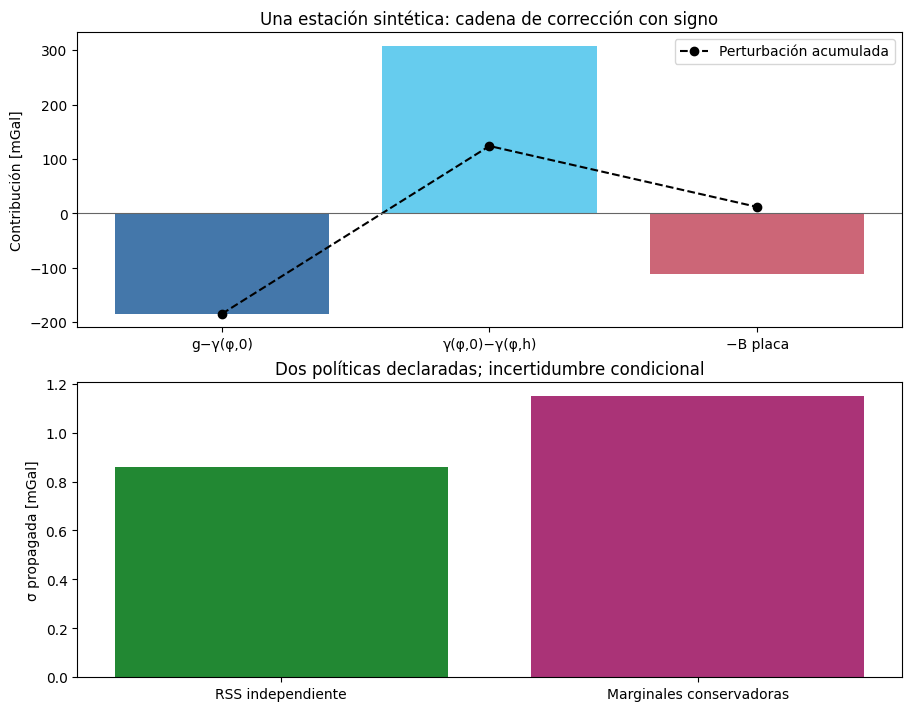

In [2]:
import copy, json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Ejecutar el pipeline M01 real sobre el control de estación con ambas políticas declaradas de incertidumbre.
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
from gravity_processing import process_survey
q = json.loads((root / 'docs/methods/gravity-processing/examples/station-control.json').read_text(encoding='utf-8'))
base = q['dataset']; conservador = process_survey(base, q['config'])
config = copy.deepcopy(q['config']); config['uncertainty_model'] = 'independent_first_order'
independiente = process_survey(base, config)
h = conservador['dataset']['history']; g = base['stations'][0]['value_mgal']
terminos = [g + h[0]['additions_mgal'][0], h[1]['additions_mgal'][0], h[2]['additions_mgal'][0]]
acumulada = np.cumsum(terminos)
assert np.isclose(acumulada[-1], conservador['dataset']['stations'][0]['value_mgal'], atol=1e-9, rtol=0)
fig,(ax,bx)=plt.subplots(2,1,figsize=(9,7),constrained_layout=True)
etiq=['g−γ(φ,0)','γ(φ,0)−γ(φ,h)','−B placa']
ax.bar(etiq,terminos,color=['#4477aa','#66ccee','#cc6677']); ax.plot(range(3),acumulada,'ko--',label='Perturbación acumulada')
ax.axhline(0,color='.4',lw=.8); ax.set(ylabel='Contribución [mGal]',title='Una estación sintética: cadena de corrección con signo'); ax.legend()
bx.bar(['RSS independiente','Marginales conservadoras'],[independiente['processing']['uncertainty_mgal'][0],conservador['processing']['uncertainty_mgal'][0]],color=['#228833','#aa3377'])
bx.set(ylabel='σ propagada [mGal]',title='Dos políticas declaradas; incertidumbre condicional')
print('derivada mGal:',acumulada[-1]); print('componentes:',conservador['processing']['uncertainty_components_mgal']); print('método completo aceptado:',conservador['processing']['full_method_accepted'])
plt.show()


## Resumen

Nunca infiera referencia, unidades, signo, datum o tratamiento topográfico solo a partir de un número.


## Referencias

- https://pubs.usgs.gov/tm/02/d04/tm2d4.pdf
- https://www.fatiando.org/harmonica/latest/api/index.html